# Radiación del cuerpo negro fig1.2
### Física Electrónica - UTN FRA
*Cuaderno interactivo adaptado para Google Colab.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)


In [1]:

!pip install -q quantities

import sys 
!{sys.executable} -m pip install --user quantities
!{sys.executable} -m pip install --user numpy
!{sys.executable} -m pip install --user matplotlib
!{sys.executable} -m pip install --user scipy
!{sys.executable} -m pip install --user pylab





     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 kB 4.6 MB/s eta 0:00:00
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
ERROR: Could not find a version that satisfies the requirement pylab (from versions: none)
ERROR: No matching distribution found for pylab


# Ley de PLank de radiación del Cuerpo Negro

$$B \lambda(T) = \frac{2 \pi h c^2 / \lambda^5}{e^{hc / \lambda k_B T} - 1}$$

1 h (Planck_constant)
1 k (Boltzmann_constant)
UnitConstant('Boltzmann_constant', 1.3806504e-23 * J/K, 'k')
UnitConstant('Planck_constant', 6.62606896e-34 * s*J, 'h')
26421.629609697076 W/(m**2*nm*sr)


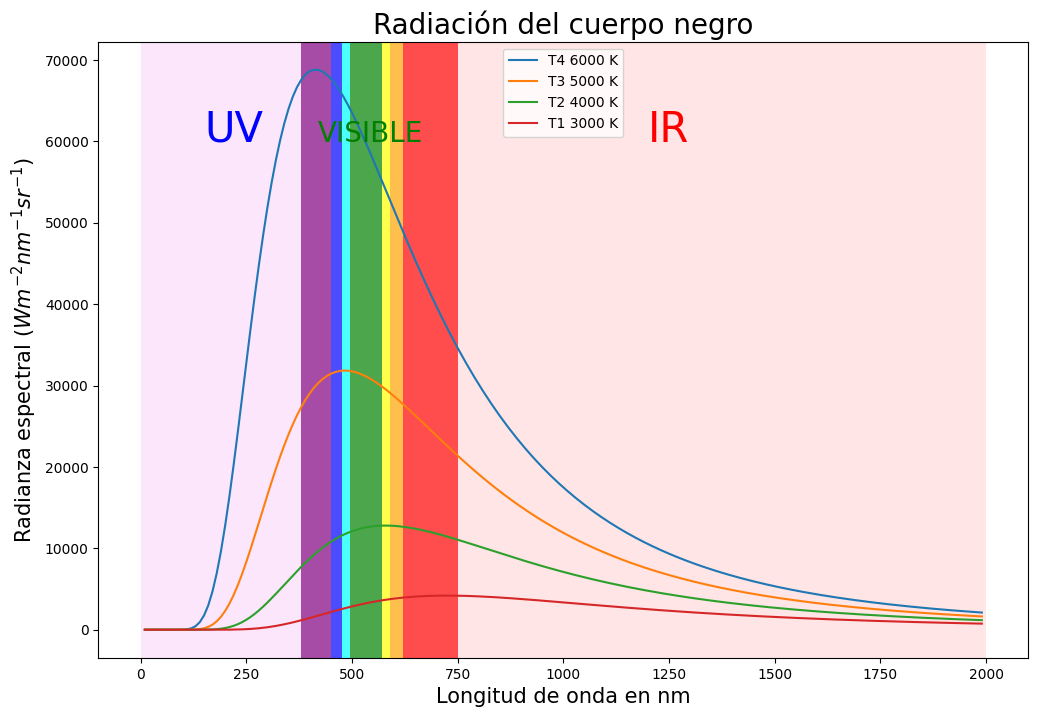

In [11]:
# -*- coding: utf-8 -*-
"""
"""
from __future__ import division

import quantities as pq
import numpy as np
import matplotlib.pyplot as plt
from IPython.html.widgets import *

print (pq.constants.Planck_constant)
print (pq.constants.Boltzmann_constant)
print(repr(pq.constants.Boltzmann_constant))
print(repr(pq.constants.Planck_constant))

def B(wl,T):
    '''wl es un array de longitudes de onda con unidades de longitud
    T es una temperatura expresada en Kelvin
    el resultado es un array de r.e. con unidades W/(m**2 * nm * sr)
    '''
    I = 2 * pq.constants.h * (pq.c)**2 / wl**5 *  \
        1 / (np.exp((pq.constants.h*pq.c \
        / (wl*pq.constants.k*T)).simplified)-1)
    return I.rescale(pq.watt/(pq.m**2 * pq.nm *pq.sr))
a=B( 5000 *pq.angstrom, 5780 *pq.K)
print (a)

T1 = 4000 * pq.Kelvin
T2 = 5000 * pq.Kelvin
T3 = 6000 * pq.Kelvin
T4 = 7000 * pq.Kelvin
#T1 = 4250 #@param {type:"slider", min:250, max:11000, step:10}
#T1=T1 * pq.Kelvin

wl = np.arange(10,2000,10) * pq.nm    # array de longitudes de onda en nanometros

fig, ax = plt.subplots(figsize=(12, 8))
T4Text=str(T4)
ax.plot(wl, B(wl,T4), label='T4 6000 K')
ax.plot(wl, B(wl,T3), label='T3 5000 K')
ax.plot(wl, B(wl,T2), label='T2 4000 K')
ax.plot(wl, B(wl,T1), label='T1 3000 K')
ax.legend()
ax.set_title(u'Radiación del cuerpo negro')
ax.title.set_fontsize(20)
ax.set_xlabel('Longitud de onda en nm')
ax.xaxis.label.set_fontsize(15)
ax.set_ylabel('Radianza espectral $(W m^{-2}nm^{-1}sr^{-1})$')
ax.yaxis.label.set_fontsize(15)
ax.axvspan(0,380,facecolor = 'violet',alpha = 0.2)
ax.axvspan(380,450, facecolor='purple', alpha = 0.7)
ax.axvspan(450,476, facecolor='blue', alpha = 0.7)
ax.axvspan(476,495, facecolor='cyan', alpha = 0.7)
ax.axvspan(495,570, facecolor='green', alpha = 0.7)
ax.axvspan(570,590, facecolor='yellow', alpha = 0.7)
ax.axvspan(590,620, facecolor='orange', alpha = 0.7)
ax.axvspan(620,750, facecolor='red', alpha = 0.7)

#interact(plot_filter_resp, fc=(35,50,1), D=(2,20,1), L=(20, 200, 10))


#ax.axvspan(400,700, facecolor='yellow', alpha = 0.5)
ax.axvspan(750,2000, facecolor ='red', alpha = 0.1)
ax.text(150,6e4, 'UV', fontsize=30, color = 'b')
ax.text(1200,6e4, 'IR', fontsize=30, color = 'r')
ax.text(420,6e4, 'VISIBLE', fontsize=20, color = 'green');




In [4]:
# -*- coding: utf-8 -*-
"""
"""
from __future__ import division

import quantities as pq
import numpy as np
import matplotlib.pyplot as plt


def B(wl,T):
    '''wl es un array de longitudes de onda con unidades de longitud
    T es una temperatura expresada en Kelvin
    el resultado es un array de r.e. con unidades W/(m**2 * nm * sr)
    '''
    I = 2 * pq.constants.h * (pq.c)**2 / wl**5 *  \
        1 / (np.exp((pq.constants.h*pq.c \
        / (wl*pq.constants.k*T)).simplified)-1)
    return I.rescale(pq.watt/(pq.m**2 * pq.nm *pq.sr))

def plot_radiacion(T):
    wl = np.arange(10,2000,10) * pq.nm    # array de longitudes de onda en nanometros

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.plot(wl, B(wl,T), label='T = {} K'.format(T.magnitude))
    ax.legend()
    ax.set_title(u'Radiación del cuerpo negro')
    ax.title.set_fontsize(20)
    ax.set_xlabel('Longitud de onda en nm')
    ax.xaxis.label.set_fontsize(15)
    ax.set_ylabel('Radianza espectral $(W m^{-2}nm^{-1}sr^{-1})$')
    ax.yaxis.label.set_fontsize(15)
    ax.axvspan(0,380,facecolor = 'violet',alpha = 0.2)
    ax.axvspan(380,450, facecolor='purple', alpha = 0.5)
    ax.axvspan(450,476, facecolor='blue', alpha = 0.5)
    ax.axvspan(476,495, facecolor='cyan', alpha = 0.4)
    ax.axvspan(495,570, facecolor='green', alpha = 0.4)
    ax.axvspan(570,590, facecolor='yellow', alpha = 0.4)
    ax.axvspan(590,620, facecolor='orange', alpha = 0.4)
    ax.axvspan(620,750, facecolor='red', alpha = 0.4)
    ax.axvspan(750,2000, facecolor ='red', alpha = 0.1)
    ax.text(150,6e4, 'UV', fontsize=30, color = 'b')
    ax.text(1200,6e4, 'IR', fontsize=30, color = 'r')
    ax.text(420,6e4, 'VISIBLE', fontsize=20, color = 'green');
    plt.grid()

interact(plot_radiacion, T1=(250, 11000, 10));

ValueError: ignored

3126666245501.6094


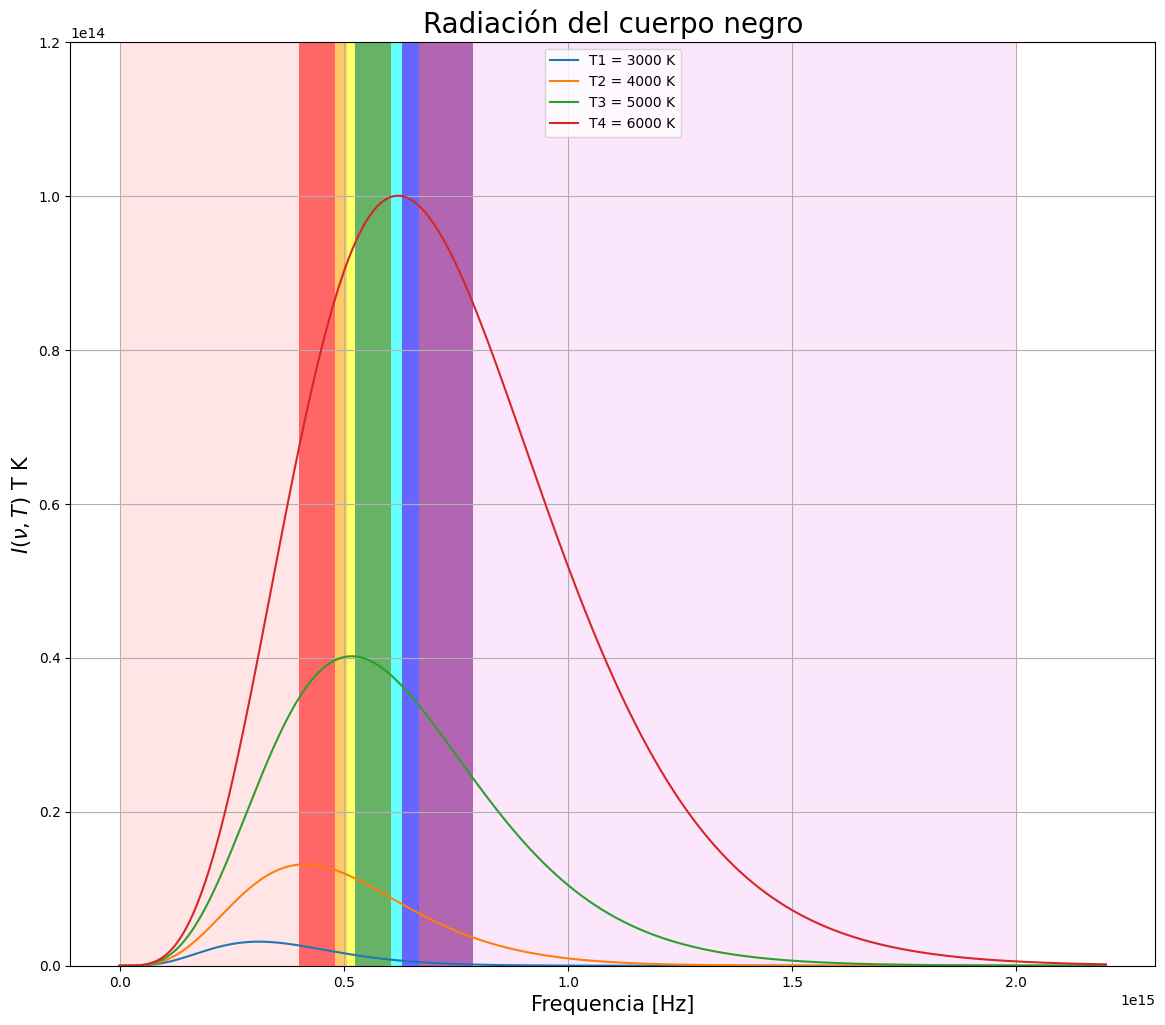

In [5]:
from scipy.constants import h, c, k
from pylab import *
from numpy import *
from IPython.html.widgets import *

#https://www.w3schools.com/python/python_lambda.asp 
"""Este lambda no tiene nada que ver con la parte fisica es una forma de declarar funciones breves en Python """
# Ley de Planck

#P = lambda nu, T: 2*h*nu**3/c**2 * 1/(exp(h*nu/(k*T))-1)
#P = lambda nu, T: 8*3.14*2*h*nu**3/c**3 * 1/(exp(h*nu/(k*T))-1)
P = lambda nu, T: 2*pi*h*c**2/(c/nu)**5 * 1/(exp(h*c/((c/nu)*k*T))-1)# reemplazada por mi

#nu = linspace(1.0e10, 1.0e15, 1.0e3)
#nu = linspace(100000000, 1000000000000000,1000)
nu = linspace(1, 2.2e15, 10000)

T1 = 3000
T2 = 4000
T3 = 5000
T4 = 6000

fig, ax = plt.subplots(figsize=(14, 12))
plot(nu, P(nu,T1), label = 'T1 = 3000 K')
plot(nu, P(nu,T2), label = 'T2 = 4000 K')
plot(nu, P(nu,T3), label = 'T3 = 5000 K')
plot(nu, P(nu,T4), label = 'T4 = 6000 K')
#plot(nu, W(nu,T), label = 'Ley Wien')
#plot(nu, R(nu,T), label = 'Ley Rayleigh Jean')
print(max(P(nu,T1)))
ylim(min(P(nu,T4)),1.2*max(P(nu,T4)))

ax.set_title(u'Radiación del cuerpo negro')
ax.title.set_fontsize(20)

ax.xaxis.label.set_fontsize(15)
ax.set_ylabel('Radianza espectral $(W m^{-2}nm^{-1}sr^{-1})$')
ax.yaxis.label.set_fontsize(15)

ax.axvspan(1e10,400e12,facecolor = 'red',alpha = 0.1)
ax.axvspan(4e14,4.8e14, facecolor='red', alpha = 0.6)
ax.axvspan(480e12,508e12, facecolor='orange', alpha = 0.6)
ax.axvspan(508e12,526e12, facecolor='yellow', alpha = 0.6)
ax.axvspan(526e12,606e12, facecolor='green', alpha = 0.6)
ax.axvspan(606e12,630e12, facecolor='cyan', alpha = 0.6)
ax.axvspan(630e12,668e12, facecolor='blue', alpha = .6)
ax.axvspan(668e12,789e12, facecolor='purple', alpha = 0.6)
ax.axvspan(789e12,2000e12, facecolor='violet', alpha = 0.2)

ax.axvspan(700,2000, facecolor ='red', alpha = 0.3)
axvspan(1e10, 1e11, facecolor='g', alpha=0.5)




legend()
xlabel("Frequencia [Hz]")
ylabel(r"$I(\nu, T)$ T K")
plt.grid()

In [6]:
from scipy.constants import h, c, k
from pylab import *
from numpy import *
from ipywidgets import *

# Ley de Planck
P = lambda nu, T: 2*pi*h*c**2/(c/nu)**5 * 1/(exp(h*c/((c/nu)*k*T))-1)

# Frecuencias
nu = linspace(1, 2.2e15, 10000)

# Valores de temperatura
T1 = 4000
T2 = 5000
T3 = 6000
T4 = 7000

# Función que actualiza el gráfico cuando se modifica T1
def update_plot(T1):
    fig, ax = plt.subplots(figsize=(18, 15))
    plot(nu, P(nu,T1), label = f'T1 = {T1} K')
    plot(nu, P(nu,T2), label = f'T2 = {T2} K')
    plot(nu, P(nu,T3), label = f'T3 = {T3} K')
    plot(nu, P(nu,T4), label = f'T4 = {T4} K')
    ylim(min(P(nu,T4)),1.2*max(P(nu,T4)))

    ax.set_title(u'Radiación del cuerpo negro')
    ax.title.set_fontsize(20)

    ax.xaxis.label.set_fontsize(15)
    ax.set_ylabel('Radianza espectral $(W m^{-2}nm^{-1}sr^{-1})$')
    ax.yaxis.label.set_fontsize(15)

    ax.axvspan(1e10,400e12,facecolor = 'red',alpha = 0.1)
    ax.axvspan(4e14,4.8e14, facecolor='red', alpha = 0.4)
    ax.axvspan(480e12,508e12, facecolor='orange', alpha = 0.4)
    ax.axvspan(508e12,526e12, facecolor='yellow', alpha = 0.4)
    ax.axvspan(526e12,606e12, facecolor='green', alpha = 0.4)
    ax.axvspan(606e12,630e12, facecolor='cyan', alpha = 0.4)
    ax.axvspan(630e12,668e12, facecolor='blue', alpha = .5)
    ax.axvspan(668e12,789e12, facecolor='purple', alpha = 0.4)
    ax.axvspan(789e12,2000e12, facecolor='violet', alpha = 0.2)

    ax.axvspan(700,2000, facecolor ='red', alpha = 0.3)
    axvspan(1e10, 1e11, facecolor='g', alpha=0.5)

    legend()
    xlabel("Frequencia [Hz]")
    ylabel(r"$I(\nu, T)$ T K")
    plt.grid()

# Crear control deslizante para T1
slider_T1 = FloatSlider(min=1000, max=10000, step=10, value=T1)
interactive_plot = interactive(update_plot, T1=slider_T1)


Ley de Planck en dependiendo de nu (frecuencia) y longitud de onda
$$ I(\nu, T) = \frac{2h\nu^3}{c^2} 
\frac{1}{e^{\frac{h\nu}{kT}} - 1} \qquad 
\\
I(\lambda, T) d\lambda = \frac{2hc^2}{\lambda^5} \frac{1}{e^{\frac{hc}{\lambda kT}} - 1} d\lambda$$
Ley de Wien $$ I(\nu, T) = \frac{2h\nu^3}{c^2}e^{-\frac{h\nu}{kT}}$$
Ley de Rayleigh-Jeans $$ I(\nu, T) = \frac{2\nu^2 kT}{c^2}$$

In [8]:
#https://www.w3schools.com/python/python_lambda.asp 
"""Este lambda no tiene nada que ver con la parte fisica es una forma de declarar funciones breves en Python """
# Ley de Planck
#nu Frecuencia
P = lambda nu, T: 2*h*nu**3/c**2 * (1/((exp(h*nu/(k*T))-1)))
Pl = lambda l, T: 2*h*c**2/l**5 * 1/(exp(h*c/(l*k*T))-1)
# Ley de Wien
W = lambda nu, T: 2*h*nu**3/c**2 * exp(-h*nu/(k*T))
# Ley de Rayleight 
R = lambda nu, T: 2*nu**2*k*T/c**2

8.340198361556176e-09


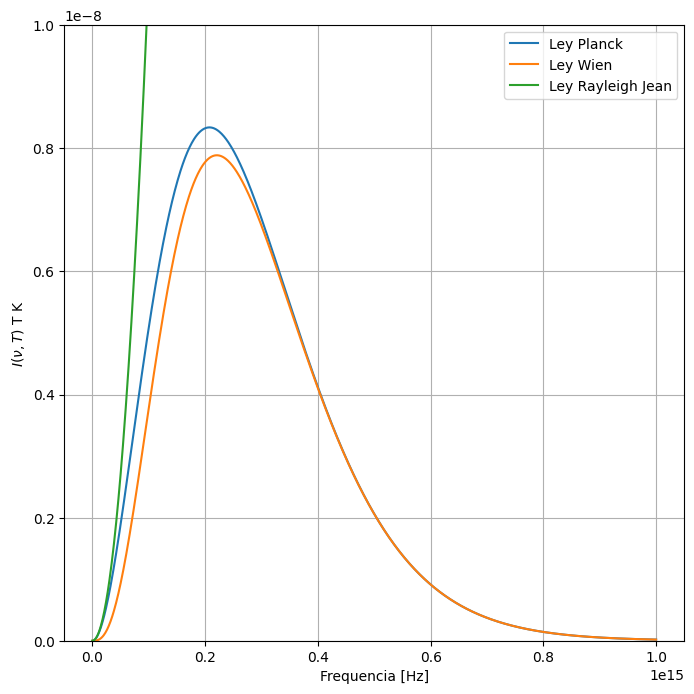

In [9]:
#nu = linspace(1.0e10, 1.0e15, 1.0e3)
#nu = linspace(100000000, 1000000000000000,1000)
nu = linspace(1, 1e15, 1000)
T = 3530 #@param {type:"slider", min:250, max:11000, step:10}
fig, ax = plt.subplots(figsize=(8, 8))
plot(nu, P(nu,T), label = 'Ley Planck')
plot(nu, W(nu,T), label = 'Ley Wien')
plot(nu, R(nu,T), label = 'Ley Rayleigh Jean')
print(max(P(nu,T)))
ylim(min(P(nu,T)),1.2*max(P(nu,T)))
legend()
xlabel("Frequencia [Hz]")
ylabel(r"$I(\nu, T)$ T K")
plt.grid()



In [10]:
#otra manera de resolverlo es usando la libreria  astropy
#https://docs.astropy.org/en/stable/index.html

import numpy as np
import matplotlib.pyplot as plt
from astropy.modeling.blackbody import blackbody_lambda
from astropy import units as u
T = 5800*u.K
wavelength = np.linspace(100,5000,1000)*u.nm
black_body_intensity=blackbody_lambda(wavelength,T)
plt.plot(wavelength,black_body_intensity)

plt.xlabel('Longitud de onda en nm')
plt.ylabel('Intensidad')
plt.grid()
plt.show()


ModuleNotFoundError: ignored

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.modeling.blackbody import blackbody_lambda
from astropy.modeling.blackbody import lambdanmax
from astropy import units as u

# Parámetros iniciales
T = 5800 * u.K
wavelength = np.linspace(100, 5000, 1000) * u.nm

# Función para actualizar la gráfica
def update(T):
    # Cálculo de la intensidad del cuerpo negro
    black_body_intensity = blackbody_lambda(wavelength, T)
    
    # Valor de lambda_max
    lambda_max = lambdanmax(T)
    
    # Actualizar la gráfica
    plt.cla()
    plt.plot(wavelength, black_body_intensity)
    plt.xlabel('Longitud de onda (nm)')
    plt.ylabel('Intensidad')
    plt.grid(True)
    plt.title(f'Temperatura: {T.value} K, lambda_max: {lambda_max.value:.2f} nm')
    plt.axvline(x=lambda_max.value, color='r', linestyle='--')
    plt.text(lambda_max.value + 50, np.max(black_body_intensity)/2, f'lambda_max: {lambda_max.value:.2f} nm', color='r')

# Crear la figura
fig, ax = plt.subplots()
update(T)

# Crear un slider interactivo para ajustar la temperatura
from matplotlib.widgets import Slider

ax_T = plt.axes([0.2, 0.05, 0.6, 0.03])
slider_T = Slider(ax_T, 'Temperatura (K)', 100, 10000, valinit=T.value)

# Función de actualización para el slider
def update_slider(val):
    T.value = val
    update(T)

slider_T.on_changed(update_slider)

plt.show()


ModuleNotFoundError: ignored

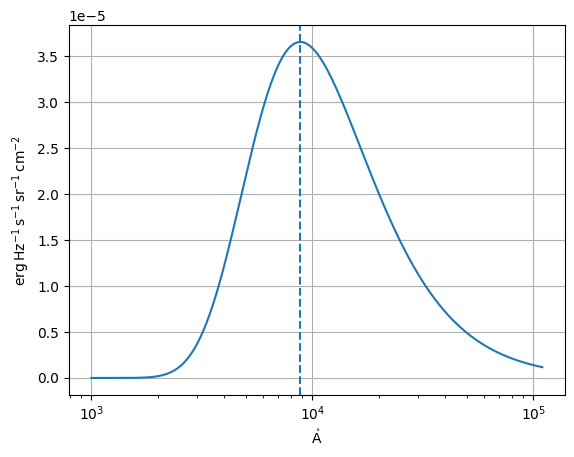

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from astropy.modeling.models import BlackBody
from astropy import units as u
from astropy.visualization import quantity_support

bb = BlackBody(temperature=5778*u.K)
wav = np.arange(1000, 110000) * u.AA
flux = bb(wav)

with quantity_support():
    plt.figure()
    plt.semilogx(wav, flux)
    plt.axvline(bb.nu_max.to(u.AA, equivalencies=u.spectral()).value, ls='--')
    plt.grid()
    plt.show()

$$c = \lambda \nu$$








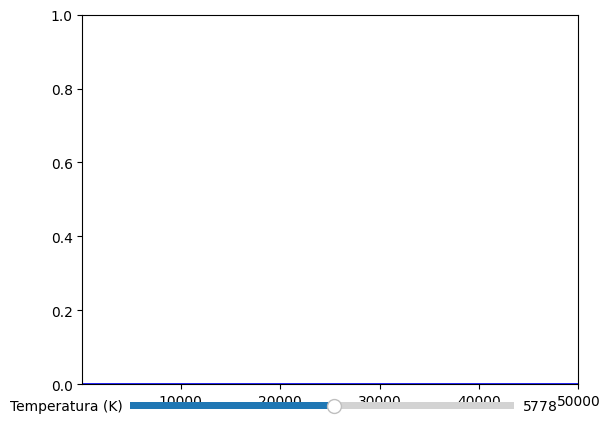

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.modeling.models import BlackBody
from astropy import units as u
from astropy.visualization import quantity_support
from matplotlib.widgets import Slider

# Crear una instancia del modelo BlackBody
cuerpo_negro = BlackBody()

# Rango de longitud de onda
longitud_onda = np.linspace(100, 50000, 1000) * u.nm

# Función para calcular el flujo
def calcular_flujo(temperatura):
    cuerpo_negro.temperature = temperatura * u.K
    flujo = cuerpo_negro(longitud_onda)
    return flujo

# Crear la figura y los ejes
fig, ax = plt.subplots()

# Configurar los límites de los ejes
ax.set_xlim(100, 50000)
ax.set_ylim(0, 1)

# Dibujar la línea de flujo inicial
line, = ax.plot(longitud_onda, calcular_flujo(5778), color='blue')

# Función de actualización al modificar el valor del slider
def actualizar(valor):
    temperatura = slider_temperatura.val
    flujo = calcular_flujo(temperatura)
    line.set_ydata(flujo)
    ax.set_title(f'Temperatura: {temperatura} K')
    fig.canvas.draw_idle()

# Crear el slider interactivo
ax_slider = plt.axes([0.2, 0.05, 0.6, 0.03])
slider_temperatura = Slider(ax_slider, 'Temperatura (K)', 1000, 10000, valinit=5778)
slider_temperatura.on_changed(actualizar)

# Mostrar la gráfica
plt.show()


# Nueva sección


---



In [ ]:
TCMB = 5800 *pq.K

lmax = pq.constants.b / TCMB


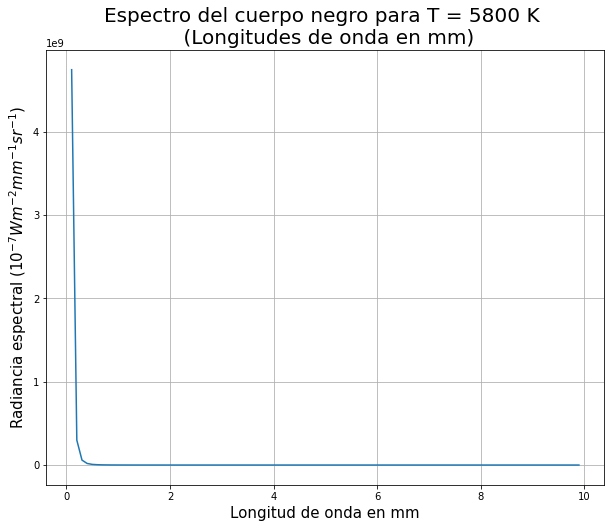

In [ ]:
wl = np.arange(0.1,10,0.1) * pq.mm
I = B(wl,TCMB).rescale(pq.watt/(pq.m**2 * pq.mm * pq.sr))

fig, ax = plt.subplots(figsize=(10, 8))
ax.plot(wl, I*1e7)
ax.set_title('Espectro del cuerpo negro para T = 5800 K \
\n (Longitudes de onda en mm)')
ax.title.set_fontsize(20)
ax.set_xlabel('Longitud de onda en mm')
ax.xaxis.label.set_fontsize(15)
ax.set_ylabel('Radiancia espectral ($10^{-7} W m^{-2} mm^{-1} sr^{-1}$)')
ax.yaxis.label.set_fontsize(15)
ax.grid()

In [ ]:
def B_f(wf,T):
    '''wf es un array de frecuencias con unidades en GHz
    T es una temperatura expresada en Kelvin
    el resultado es un array de radiancias espectrales
    con unidades W/(m**2 x GHz x sr)
    '''
    wf = wf.rescale(pq.hertz)
    I = 2 * pq.constants.h * wf**3 / pq.c**2 * 1 \
        / (np.exp((pq.constants.h*wf \
        / (pq.constants.k*T)).simplified)-1)
    return I.rescale(pq.watt/(pq.m**2 * pq.gigahertz *pq.sr))

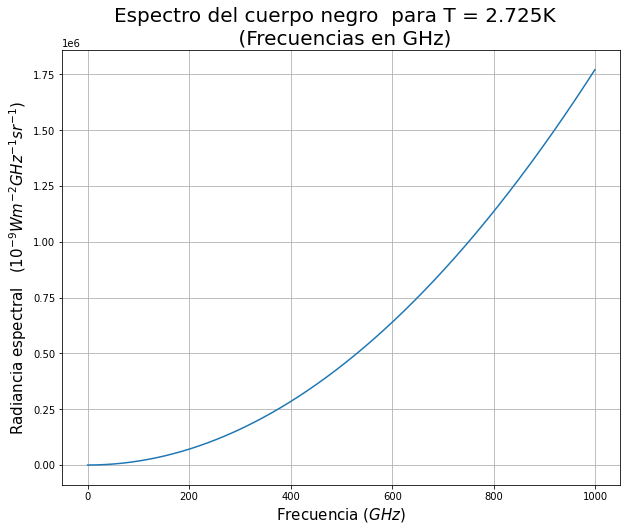

In [ ]:
wf = np.arange(0.1,1000,1)* pq.gigahertz
I = B_f(wf,TCMB)

fig, ax = plt.subplots(figsize=(10, 8))
ax.plot(wf, I*10**9) # Escalamos las unidades
ax.set_title('Espectro del cuerpo negro  para T = 2.725K \
 \n (Frecuencias en GHz)')
ax.title.set_fontsize(20)
ax.set_xlabel('Frecuencia ($GHz)$')
ax.xaxis.label.set_fontsize(15)
ax.set_ylabel('Radiancia espectral   $(10^{-9} W m^{-2} GHz^{-1} sr^{-1})$')
ax.yaxis.label.set_fontsize(15)
ax.grid()